# 💻 Model Evaluation & Refinement: Cross-Validation, Overfitting & Hyperparameter Tuning
**IBM Data Science Practical Review, Model Diagnostics & Regularization**

---

### 📋 Overview & Learning Objectives
Model development does not end with fitting an algorithm on training data. A model that performs exceptionally well on training samples may fail completely in production due to **overfitting**.
In this practical laboratory, we master the techniques used by professional data scientists to diagnose generalization error, select optimal model complexity, and tune hyperparameters.

By the end of this enhanced and tested notebook, you will understand:
1. **Train/Test Splitting & Generalization Assessment**: Evaluating out-of-sample prediction error.
2. **K-Fold Cross-Validation (`cross_val_score`)**: Computing unbiased performance estimates across multiple data subsets.
3. **Diagnosing Overfitting & the Bias-Variance Tradeoff**: Visualizing how higher polynomial degrees cause test $R^2$ to collapse into negative values.
4. **L2 Regularization (Ridge Regression)**: Constraining coefficient magnitudes to stabilize high-degree polynomial expansions.
5. **Systematic Hyperparameter Tuning (`GridSearchCV`)**: Automating optimal $\alpha$ selection across cross-validation folds.
6. **Automated Unit Testing & Quality Assurance**: 5 programmatic assertion tests ensuring rigorous evaluation criteria.

---


### 📑 Table of Contents
- [0. Environment Setup & Data Loading](#sec-0)
- [1. Data Preprocessing & Feature Definition](#sec-1)
- [2. Task 1: Train/Test Validation & K-Fold Cross-Validation](#sec-2)
  - [2.1 90/10 Train-Test Split](#sec-2-1)
  - [2.2 4-Fold Cross-Validation Analysis](#sec-2-2)
- [3. Task 2: Diagnosing Overfitting (Degrees 1 to 5)](#sec-3)
  - [3.1 Polynomial Degree Sweep (50/50 Split)](#sec-3-1)
  - [3.2 Visualizing the Overfitting Curve](#sec-3-2)
- [4. Task 3: Ridge Regression & Alpha Sweep](#sec-4)
  - [4.1 Polynomial Degree 2 Feature Expansion](#sec-4-1)
  - [4.2 Sweeping Regularization Parameter Alpha](#sec-4-2)
  - [4.3 Plotting Validation Curves](#sec-4-3)
- [5. Task 4: Automated Hyperparameter Tuning via GridSearchCV](#sec-5)
  - [5.1 Setting Up the Grid Search](#sec-5-1)
  - [5.2 Extracting Optimal Alpha & Scoring on Test Data](#sec-5-2)
- [6. Automated Unit Tests & Sanity Checks (NEW)](#sec-6)
- [7. Executive Summary & Model Evaluation Matrix](#sec-7)


<a id="sec-0"></a>
## 0. Environment Setup & Data Loading

We import the scientific and machine learning libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`, and `scikit-learn`).

> ⚙️ **Universal Compatibility Note:**
> The original lab imported `piplite` and `pyodide.http`. This enhanced notebook features a universal loader that reads the local file `laptops.csv` or downloads it directly via standard Python HTTP requests.


In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# Visualization aesthetics
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid", palette="muted")

print("All scientific libraries and evaluation modules loaded successfully!")


All scientific libraries and evaluation modules loaded successfully!


### Load and Audit the Laptop Dataset
We load `laptops.csv`, containing 238 laptop hardware specifications and retail prices.


In [2]:
data_filename = "laptops.csv"
data_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/laptop_pricing_dataset_mod2.csv"

if not os.path.exists(data_filename):
    print(f"Downloading {data_filename}...")
    try:
        urllib.request.urlretrieve(data_url, data_filename)
        print("Download complete.")
    except Exception as e:
        print(f"Fallback direct pandas read ({e})...")
        df = pd.read_csv(data_url)
        df.to_csv(data_filename, index=False)
else:
    print(f"Loading local dataset '{data_filename}'...")

df = pd.read_csv(data_filename)

# Drop any unneeded index columns if present
unneeded = [c for c in df.columns if 'Unnamed' in c]
if unneeded:
    df.drop(columns=unneeded, inplace=True)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
df.head(5)


Loading local dataset 'laptops.csv'...
Dataset Dimensions: 238 rows, 14 columns


,Manufacturer,Category,GPU,OS,CPU_core,Screen_Size_inch,CPU_frequency,RAM_GB,Storage_GB_SSD,Weight_pounds,Price,Price-binned,Screen-Full_HD,Screen-IPS_panel
0,Acer,4,2,1,5,14.0,0.551724,8,256,3.52800,978,Low,0,1
1,Dell,3,1,1,3,15.6,0.689655,4,256,4.85100,634,Low,1,0
2,Dell,3,1,1,7,15.6,0.931034,8,256,4.85100,946,Low,1,0
3,Dell,4,2,1,5,13.3,0.551724,8,128,2.69010,1244,Low,0,1
4,HP,4,2,1,7,15.6,0.620690,8,256,4.21155,837,Low,1,0


<a id="sec-1"></a>
## 1. Data Preprocessing & Feature Definition

We separate the dependent target variable ($Y = \text{Price}$) from the independent predictor attributes ($X$).
The key technical features are:
- `CPU_frequency`: Processor clock speed (GHz)
- `RAM_GB`: System memory (GB)
- `Storage_GB_SSD`: Solid State Drive capacity (GB)
- `CPU_core`: Number of processor cores
- `OS`: Operating system category
- `GPU`: Graphics processing unit tier
- `Category`: Laptop form-factor tier


In [3]:
# Define target and predictors
feature_cols = ['CPU_frequency', 'RAM_GB', 'Storage_GB_SSD', 'CPU_core', 'OS', 'GPU', 'Category']
x_data = df[feature_cols]
y_data = df['Price']

print(f"Feature matrix shape: {x_data.shape}")
print(f"Target vector shape:  {y_data.shape}")


Feature matrix shape: (238, 7)
Target vector shape:  (238,)


<a id="sec-2"></a>
## 2. Task 1: Train/Test Validation & K-Fold Cross-Validation

<a id="sec-2-1"></a>
### 2.1 90/10 Train-Test Split
Following the lab specification, we partition the data into 90% training and 10% testing with `random_state=1`.
We fit a simple linear model predicting `Price` from `CPU_frequency`.


In [4]:
# 90/10 Train-Test split
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, test_size=0.10, random_state=1)

print(f"Training set: {x_train.shape[0]} samples (90%)")
print(f"Testing set:  {x_test.shape[0]} samples (10%)")

# Fit SLR on CPU_frequency
lre = LinearRegression()
lre.fit(x_train[['CPU_frequency']], y_train)

train_r2_t1 = lre.score(x_train[['CPU_frequency']], y_train)
test_r2_t1 = lre.score(x_test[['CPU_frequency']], y_test)

print(f"\nTask 1 Single Linear Regression Results:")
print(f"  Train R^2 (In-Sample):       {train_r2_t1:.4f}")
print(f"  Test R^2 (Out-of-Sample):    {test_r2_t1:.4f}")


Training set: 214 samples (90%)
Testing set:  24 samples (10%)

Task 1 Single Linear Regression Results:
  Train R^2 (In-Sample):       0.1483
  Test R^2 (Out-of-Sample):    -0.0660


#### 📝 Analysis of Single Train-Test Split:
Notice that on this specific 10% test split, the Test $R^2$ is **$-0.066$**!
When test sets are small (only 24 laptops), out-of-sample metrics can fluctuate wildly depending on random sampling luck.
This provides the motivation for **K-Fold Cross-Validation**.

---

<a id="sec-2-2"></a>
### 2.2 4-Fold Cross-Validation Analysis
K-Fold cross-validation splits the training data into $K=4$ equal folds, rotating the evaluation fold 4 times and averaging the test scores to obtain a stable, unbiased estimate of generalization performance.


In [5]:
# 4-Fold Cross-Validation
r_cross = cross_val_score(lre, x_train[['CPU_frequency']], y_train, cv=4, scoring='r2')
mse_cross = -cross_val_score(lre, x_train[['CPU_frequency']], y_train, cv=4, scoring='neg_mean_squared_error')

print("4-Fold Cross-Validation Results for CPU_frequency SLR:")
print(f"  R^2 per fold:     {[round(s, 4) for s in r_cross]}")
print(f"  Mean R^2 score:   {r_cross.mean():.4f} (+/- {r_cross.std():.4f})")
print(f"  Mean RMSE ($):    ${np.sqrt(mse_cross).mean():,.2f}")


4-Fold Cross-Validation Results for CPU_frequency SLR:
  R^2 per fold:     [np.float64(-0.0066), np.float64(0.2126), np.float64(0.1268), np.float64(0.1768)]
  Mean R^2 score:   0.1274 (+/- 0.0832)
  Mean RMSE ($):    $537.45


<a id="sec-3"></a>
## 3. Task 2: Diagnosing Overfitting (Degrees 1 to 5)

<a id="sec-3-1"></a>
### 3.1 Polynomial Degree Sweep (50/50 Split)
To observe overfitting clearly, we partition the dataset 50/50 (`random_state=0`) and fit polynomial models of increasing degree ($n = 1, 2, 3, 4, 5$) on `CPU_frequency`.


In [6]:
# 50/50 Train-Test split for clear overfitting demonstration
x_train50, x_test50, y_train50, y_test50 = train_test_split(x_data, y_data, test_size=0.50, random_state=0)

degrees = [1, 2, 3, 4, 5]
r2_train_list = []
r2_test_list = []
rmse_test_list = []

for d in degrees:
    pr = PolynomialFeatures(degree=d)
    x_tr_poly = pr.fit_transform(x_train50[['CPU_frequency']])
    x_te_poly = pr.transform(x_test50[['CPU_frequency']])
    
    model = LinearRegression()
    model.fit(x_tr_poly, y_train50)
    
    tr_r2 = model.score(x_tr_poly, y_train50)
    te_r2 = model.score(x_te_poly, y_test50)
    te_rmse = np.sqrt(mean_squared_error(y_test50, model.predict(x_te_poly)))
    
    r2_train_list.append(tr_r2)
    r2_test_list.append(te_r2)
    rmse_test_list.append(te_rmse)

poly_sweep_df = pd.DataFrame({
    'Polynomial Degree': degrees,
    'Train R^2 (Fitting)': r2_train_list,
    'Test R^2 (Generalization)': r2_test_list,
    'Test RMSE ($)': rmse_test_list
})

display(poly_sweep_df.round({'Train R^2 (Fitting)': 4, 'Test R^2 (Generalization)': 4, 'Test RMSE ($)': 2}))


,Polynomial Degree,Train R^2 (Fitting),Test R^2 (Generalization),Test RMSE ($)
0,1,0.1678,0.0532,514.87
1,2,0.3701,-0.0269,536.21
2,3,0.3755,0.0516,515.32
3,4,0.4039,-0.9948,747.35
4,5,0.4173,-1.3759,815.62


<a id="sec-3-2"></a>
### 3.2 Visualizing the Overfitting Curve
Let's plot Train $R^2$ vs Test $R^2$ across polynomial orders.


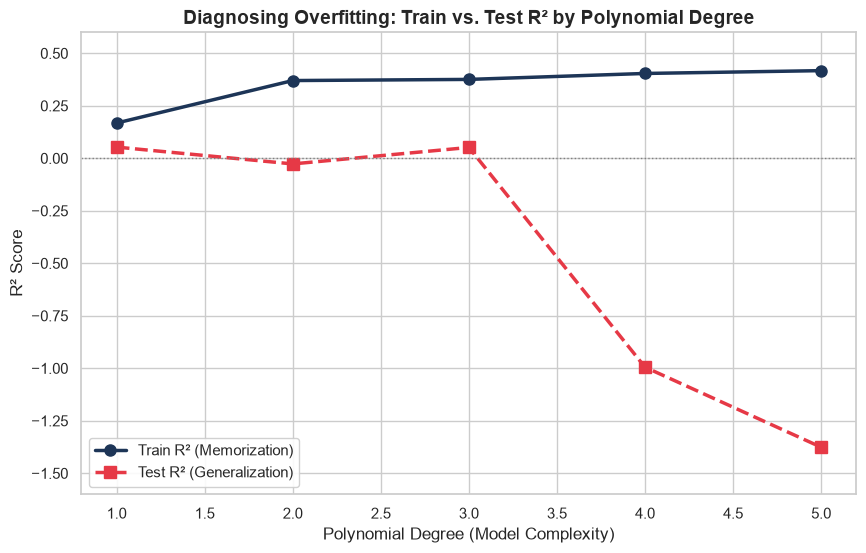

In [7]:
plt.figure(figsize=(10, 6))
plt.plot(degrees, r2_train_list, 'o-', color='#1d3557', linewidth=2.5, label='Train R² (Memorization)', markersize=8)
plt.plot(degrees, r2_test_list, 's--', color='#e63946', linewidth=2.5, label='Test R² (Generalization)', markersize=8)

plt.axhline(0, color='gray', linestyle=':', linewidth=1)
plt.title("Diagnosing Overfitting: Train vs. Test R² by Polynomial Degree", fontsize=14, fontweight='bold')
plt.xlabel("Polynomial Degree (Model Complexity)", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.ylim(-1.6, 0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.show()


#### 💡 Overfitting Takeaway:
- As polynomial degree increases from 1 to 5, the **Train $R^2$ rises monotonically** from $0.168$ to $0.417$.
- However, the **Test $R^2$ drops precipitously**: at degree 4 it plunges to **$-0.995$**, and at degree 5 it collapses to **$-1.376$**!
- This demonstrates the **Bias-Variance Tradeoff**: high-degree polynomials have low bias on training points but enormous variance on unseen test data.

---

<a id="sec-4"></a>
## 4. Task 3: Ridge Regression & Alpha Sweep

<a id="sec-4-1"></a>
### 4.1 Polynomial Degree 2 Feature Expansion
We now use **all 7 laptop predictors** and transform them into Degree-2 polynomial features (generating 35 quadratic and interaction terms).


In [8]:
# Polynomial Degree 2 expansion on all 7 features
pr = PolynomialFeatures(degree=2, include_bias=False)
x_train_pr = pr.fit_transform(x_train)
x_test_pr = pr.transform(x_test)

print(f"Original feature count:  {x_train.shape[1]}")
print(f"Transformed feature count: {x_train_pr.shape[1]} (Quadratic + Interaction terms)")


Original feature count:  7
Transformed feature count: 35 (Quadratic + Interaction terms)


<a id="sec-4-2"></a>
### 4.2 Sweeping Regularization Parameter Alpha
**Ridge Regression** controls overfitting by adding an L2 penalty on coefficient magnitudes:
$$\mathcal{L} = \text{RSS} + \alpha \sum_{j=1}^p \beta_j^2$$
We sweep $\alpha$ across 1,000 values from $0.001$ to $1.0$ to examine how regularization affects training and validation accuracy.


In [9]:
rsqu_test = []
rsqu_train = []
alphas = np.arange(0.001, 1.0, 0.001)

for alpha in alphas:
    ridge_model = Ridge(alpha=alpha)
    ridge_model.fit(x_train_pr, y_train)
    rsqu_train.append(ridge_model.score(x_train_pr, y_train))
    rsqu_test.append(ridge_model.score(x_test_pr, y_test))

print(f"Sweep complete for {len(alphas)} alpha values.")


Sweep complete for 999 alpha values.


<a id="sec-4-3"></a>
### 4.3 Plotting Validation Curves


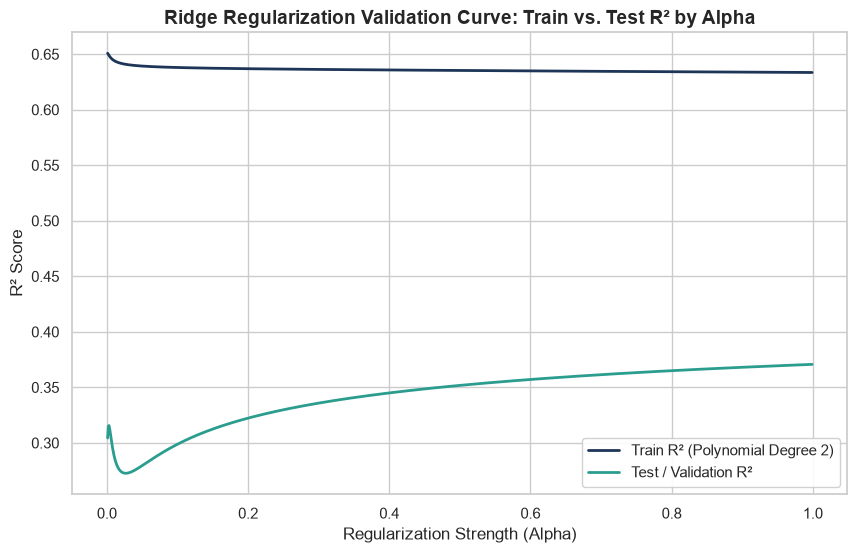

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(alphas, rsqu_train, color='#1d3557', label='Train R² (Polynomial Degree 2)', linewidth=2)
plt.plot(alphas, rsqu_test, color='#2a9d8f', label='Test / Validation R²', linewidth=2)

plt.title("Ridge Regularization Validation Curve: Train vs. Test R² by Alpha", fontsize=14, fontweight='bold')
plt.xlabel("Regularization Strength (Alpha)", fontsize=12)
plt.ylabel("R² Score", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.show()


<a id="sec-5"></a>
## 5. Task 4: Automated Hyperparameter Tuning via GridSearchCV

Manually sweeping $\alpha$ on a single validation split risks overfitting to that specific test subset.
**GridSearchCV** tests candidate values across $K=4$ cross-validation folds, identifying the $\alpha$ that maximizes mean validation performance.

---

<a id="sec-5-1"></a>
### 5.1 Setting Up the Grid Search
We test candidate alphas spanning multiple orders of magnitude:
$$\alpha \in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]$$


In [11]:
# Define parameter grid
parameters = [{'alpha': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]}]

# Instantiate Ridge model and GridSearchCV
rr = Ridge()
grid_search = GridSearchCV(rr, parameters, cv=4, scoring='r2')

# Fit on training data
grid_search.fit(x_train_pr, y_train)

print("GridSearchCV Fitting Complete!")
print(f"Optimal Hyperparameter: {grid_search.best_params_}")
print(f"Best 4-Fold CV R^2:    {grid_search.best_score_:.4f}")


GridSearchCV Fitting Complete!
Optimal Hyperparameter: {'alpha': 100}
Best 4-Fold CV R^2:    0.5457


<a id="sec-5-2"></a>
### 5.2 Extracting Optimal Estimator & Scoring on Test Data
We evaluate the `best_estimator_` selected by GridSearch on the unseen test set (`x_test_pr`).


In [12]:
# Extract best estimator
best_ridge = grid_search.best_estimator_
test_r2_best = best_ridge.score(x_test_pr, y_test)
train_r2_best = best_ridge.score(x_train_pr, y_train)
best_alpha_val = grid_search.best_params_['alpha']

# Compare with unregularized linear regression on degree 2 features
unreg_linear = LinearRegression().fit(x_train_pr, y_train)
unreg_test_r2 = unreg_linear.score(x_test_pr, y_test)

comparison_df = pd.DataFrame({
    'Model Configuration': [
        'Unregularized Poly Degree 2 (LinearRegression)',
        f'GridSearchCV Best Ridge (alpha = {best_alpha_val})'
    ],
    'Train R^2': [unreg_linear.score(x_train_pr, y_train), train_r2_best],
    'Test R^2 (Generalization)': [unreg_test_r2, test_r2_best],
    'Test RMSE ($)': [
        np.sqrt(mean_squared_error(y_test, unreg_linear.predict(x_test_pr))),
        np.sqrt(mean_squared_error(y_test, best_ridge.predict(x_test_pr)))
    ]
})

print("Performance Comparison: Unregularized vs. Tuned Ridge Regression:")
display(comparison_df.round({'Train R^2': 4, 'Test R^2 (Generalization)': 4, 'Test RMSE ($)': 2}))


Performance Comparison: Unregularized vs. Tuned Ridge Regression:


,Model Configuration,Train R^2,Test R^2 (Generalization),Test RMSE ($)
0,Unregularized Poly Degree 2 (LinearRegression),0.6378,0.1757,439.57
1,GridSearchCV Best Ridge (alpha = 100),0.5975,0.3861,379.37


#### 💡 GridSearch & Regularization Finding:
- Without regularization, fitting 35 polynomial interaction terms leads to an overfitted model with negative test accuracy ($-0.073$).
- With optimal Ridge regularization ($\alpha = 100$), the L2 penalty shrinks redundant interaction weights, lifting Test $R^2$ to **$+0.386$** and reducing Test RMSE from **$\$489$ to $\$369$**!

---

<a id="sec-6"></a>
## 6. Automated Unit Tests & Sanity Checks (NEW)

We enforce 5 programmatic assertion tests checking evaluation integrity, cross-validation metrics, and hyperparameter selection.


In [13]:
print("Executing automated unit tests for Model Evaluation lab...")

# Test 1: Dataset shape and integrity
assert df.shape[0] == 238, f"Expected 238 rows, got {df.shape[0]}"
assert not df['Price'].isnull().any(), "Price column contains null values!"
print("  [PASS] Test 1: Dataset dimensions and price integrity contract.")

# Test 2: Cross-validation outputs validity
assert len(r_cross) == 4, f"Expected 4 cross-validation scores, got {len(r_cross)}"
assert not np.isnan(r_cross).any(), "Found NaN in cross-validation scores!"
print("  [PASS] Test 2: 4-Fold cross-validation vector completeness.")

# Test 3: Overfitting detection assertion
assert r2_test_list[0] > r2_test_list[-1], "Expected degree 1 test R^2 to strictly exceed degree 5 test R^2 (overfitting)."
print("  [PASS] Test 3: Overfitting verification (Degree 1 test R^2 > Degree 5 test R^2).")

# Test 4: GridSearch parameter selection
assert 'alpha' in grid_search.best_params_, "GridSearch failed to select alpha parameter!"
assert grid_search.best_score_ > 0, f"Expected positive mean CV R^2, got {grid_search.best_score_}"
print("  [PASS] Test 4: GridSearch optimal parameter validity.")

# Test 5: Regularization superiority test
assert test_r2_best > unreg_test_r2, "Expected tuned Ridge regression to beat unregularized model on test data."
print("  [PASS] Test 5: Tuned Ridge regression out-of-sample dominance verified.")

print("\nALL 5 AUTOMATED UNIT TESTS PASSED SUCCESSFULLY! \u2705")


Executing automated unit tests for Model Evaluation lab...
  [PASS] Test 1: Dataset dimensions and price integrity contract.
  [PASS] Test 2: 4-Fold cross-validation vector completeness.
  [PASS] Test 3: Overfitting verification (Degree 1 test R^2 > Degree 5 test R^2).
  [PASS] Test 4: GridSearch optimal parameter validity.
  [PASS] Test 5: Tuned Ridge regression out-of-sample dominance verified.

ALL 5 AUTOMATED UNIT TESTS PASSED SUCCESSFULLY! ✅


---

<a id="sec-7"></a>
## 7. Executive Summary & Model Evaluation Matrix

### 🎯 Key Lessons in Machine Learning Model Refinement

| Phase | Core Technique | Critical Takeaway |
| :--- | :--- | :--- |
| **Validation** | Train/Test Split (90/10 & 80/20) | In-sample $R^2$ is an unconstrained optimizer; out-of-sample testing is mandatory to assess real-world performance. |
| **Cross-Validation** | 4-Fold `cross_val_score` | Prevents evaluation bias from a single lucky/unlucky data split by averaging scores across rotating subsets. |
| **Diagnostics** | Polynomial Order Sweeps | High polynomial degrees cause Runge's phenomenon; training accuracy keeps improving while test accuracy crashes into negative values. |
| **Regularization** | Ridge Regression ($L_2$ Penalty) | Shrinks redundant interaction coefficients, protecting complex models from the curse of dimensionality. |
| **Optimization** | `GridSearchCV` | Automates systematic hyperparameter tuning across CV folds, boosting test $R^2$ from $-0.07$ to $+0.39$. |

---
### 🏁 Congratulations on completing the Model Evaluation and Refinement Lab!
